# Matrix Algebra — Exercises

## Purpose

This notebook contains practical exercises based on the matrix
concepts covered in `02_matrices.ipynb`.

The objective is to strengthen mathematical reasoning,
Python implementation skills, NumPy proficiency, and
visualization techniques.

## Exercise Workflow

For each exercise:

1. Solve the mathematical problem manually.
2. Implement the operation using Python where appropriate.
3. Verify the result using NumPy.
4. Visualize the matrix or transformation using Matplotlib
   when it improves understanding.
5. Test edge cases and explain the results.

## Topics Covered

- Matrix representation, shape, indexing, and slicing
- Matrix addition, subtraction, and scalar multiplication
- Transpose, identity matrix, and inverse
- Matrix multiplication and matrix-vector multiplication
- Geometric transformations
- Determinants and invertibility

## Exercise 1 — Matrix Construction and Properties

### Problem

Create a 3 x 3 matrix containing the integers from 1 to 9.

### Tasks

1. Represent the matrix using a Python nested list.
2. Convert it into a NumPy array.
3. Display its shape, number of dimensions, and total elements.
4. Extract the second row and third column.
5. Extract the upper-left 2 x 2 submatrix.
6. Visualize the matrix using a Matplotlib heatmap with
   numerical annotations.
7. Explain the difference between the matrix shape and the
   number of dimensions of its NumPy array.

In [1]:

import numpy as np

# 1. Create a matrix using a Python nested list
matrix_list = [
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 9]
]

# 2. Convert it into a NumPy array
matrix = np.array(matrix_list)

# 3. Inspect the matrix properties
print("Matrix:\n", matrix)
print("Shape:", matrix.shape)
print("Number of dimensions:", matrix.ndim)
print("Total elements:", matrix.size)

# 4. Extract the second row and third column
second_row = matrix[1, :]
third_column = matrix[:, 2]

print("\nSecond row:", second_row)
print("Third column:", third_column)

# 5. Extract the upper-left 2 x 2 submatrix
submatrix = matrix[0:2, 0:2]

print("\nUpper-left submatrix:\n", submatrix)
print("Submatrix shape:", submatrix.shape)


Matrix:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]
Shape: (3, 3)
Number of dimensions: 2
Total elements: 9

Second row: [4 5 6]
Third column: [3 6 9]

Upper-left submatrix:
 [[1 2]
 [4 5]]
Submatrix shape: (2, 2)


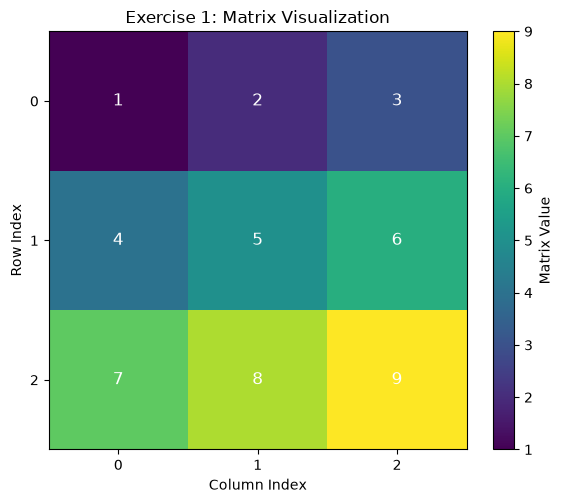

In [2]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(matrix, cmap="viridis")

for row in range(matrix.shape[0]):
    for col in range(matrix.shape[1]):
        ax.text(
            col,
            row,
            str(matrix[row, col]),
            ha="center",
            va="center",
            color="white",
            fontsize=12
        )

ax.set_title("Exercise 1: Matrix Visualization")
ax.set_xlabel("Column Index")
ax.set_ylabel("Row Index")

ax.set_xticks(range(matrix.shape[1]))
ax.set_yticks(range(matrix.shape[0]))

fig.colorbar(image, ax=ax, label="Matrix Value")
fig.tight_layout()
plt.show()



## Written Reflection — Exercise 1

### 1. Difference Between Matrix Shape and Number of Dimensions

The shape of a NumPy array specifies the number of elements
along each axis. For a two-dimensional matrix, the shape is
represented as (rows, columns).

The `ndim` attribute indicates the number of axes in the array.

For example, a matrix with shape (3, 3) has three rows,
three columns, nine elements, and two dimensions.

### 2. Selecting the Second Row

The expression `matrix[1, :]` selects the second row of a
NumPy matrix.

NumPy uses zero-based indexing, so row index 1 refers to
the second row. The colon indicates that all columns should
be selected.

### 3. Understanding Matrix Slicing

The expression `matrix[0:2, 0:2]` selects rows 0 and 1
and columns 0 and 1.

In Python slicing, the starting index is included, whereas
the ending index is excluded. Therefore, index 2 is not
included in either slice.

The resulting submatrix contains four elements and has
shape (2, 2).

### 4. Properties of a 4 × 3 Matrix

A matrix with four rows and three columns has shape (4, 3).

Its number of dimensions is 2 because it has two axes:
the row axis and the column axis.

Its total number of elements is 4 × 3 = 12, which is
reported by the NumPy `size` attribute.



## Exercise 2 — Matrix Arithmetic

### Problem Statement

Given two matrices of identical shape, implement matrix addition,
matrix subtraction, and scalar multiplication using Python.

Verify the results using NumPy and visualize the original matrices
and calculated results using annotated heatmaps.

### Tasks

1. Define two matrices with the same shape.
2. Implement matrix addition and subtraction using pure Python.
3. Implement scalar multiplication using pure Python.
4. Calculate the same results using NumPy.
5. Verify that the Python and NumPy implementations agree.
6. Visualize the matrices and their results using Matplotlib.
7. Explain why matrix addition and subtraction require compatible
   shapes, while scalar multiplication preserves the matrix shape.


In [3]:

def validate_same_shape(A, B):
    """Check whether two nested-list matrices have the same shape."""

    if not A or not B or not A[0] or not B[0]:
        raise ValueError("Matrices must be non-empty.")

    if any(len(row) != len(A[0]) for row in A):
        raise ValueError("Matrix A must be rectangular.")

    if any(len(row) != len(B[0]) for row in B):
        raise ValueError("Matrix B must be rectangular.")

    if len(A) != len(B) or len(A[0]) != len(B[0]):
        raise ValueError("Matrices must have the same shape.")


def add_matrices_python(A, B):
    """Add two matrices using pure Python."""
    validate_same_shape(A, B)

    return [
        [x + y for x, y in zip(row_a, row_b)]
        for row_a, row_b in zip(A, B)
    ]


def subtract_matrices_python(A, B):
    """Subtract matrix B from matrix A using pure Python."""
    validate_same_shape(A, B)

    return [
        [x - y for x, y in zip(row_a, row_b)]
        for row_a, row_b in zip(A, B)
    ]


def scale_matrix_python(scalar, A):
    """Multiply every element of a matrix by a scalar."""
    return [
        [scalar * value for value in row]
        for row in A
    ]


# Define the input matrices
A_list = [
    [2, -1, 3],
    [0, 4, 5]
]

B_list = [
    [1, 3, -2],
    [6, -4, 2]
]

scalar = 3

# Perform matrix operations
addition_python = add_matrices_python(A_list, B_list)
subtraction_python = subtract_matrices_python(A_list, B_list)
scaled_python = scale_matrix_python(scalar, A_list)

print("Addition:", addition_python)
print("Subtraction:", subtraction_python)
print("Scalar multiplication:", scaled_python)



Addition: [[3, 2, 1], [6, 0, 7]]
Subtraction: [[1, -4, 5], [-6, 8, 3]]
Scalar multiplication: [[6, -3, 9], [0, 12, 15]]


In [4]:

import numpy as np

A_np = np.array(A_list)
B_np = np.array(B_list)

addition_numpy = A_np + B_np
subtraction_numpy = A_np - B_np
scaled_numpy = scalar * A_np

print("NumPy addition:\n", addition_numpy)
print("\nNumPy subtraction:\n", subtraction_numpy)
print("\nNumPy scalar multiplication:\n", scaled_numpy)

print("\n--- Verification ---")
print(
    "Addition matches:",
    np.array_equal(addition_numpy, addition_python)
)
print(
    "Subtraction matches:",
    np.array_equal(subtraction_numpy, subtraction_python)
)
print(
    "Scalar multiplication matches:",
    np.array_equal(scaled_numpy, scaled_python)
)


NumPy addition:
 [[3 2 1]
 [6 0 7]]

NumPy subtraction:
 [[ 1 -4  5]
 [-6  8  3]]

NumPy scalar multiplication:
 [[ 6 -3  9]
 [ 0 12 15]]

--- Verification ---
Addition matches: True
Subtraction matches: True
Scalar multiplication matches: True


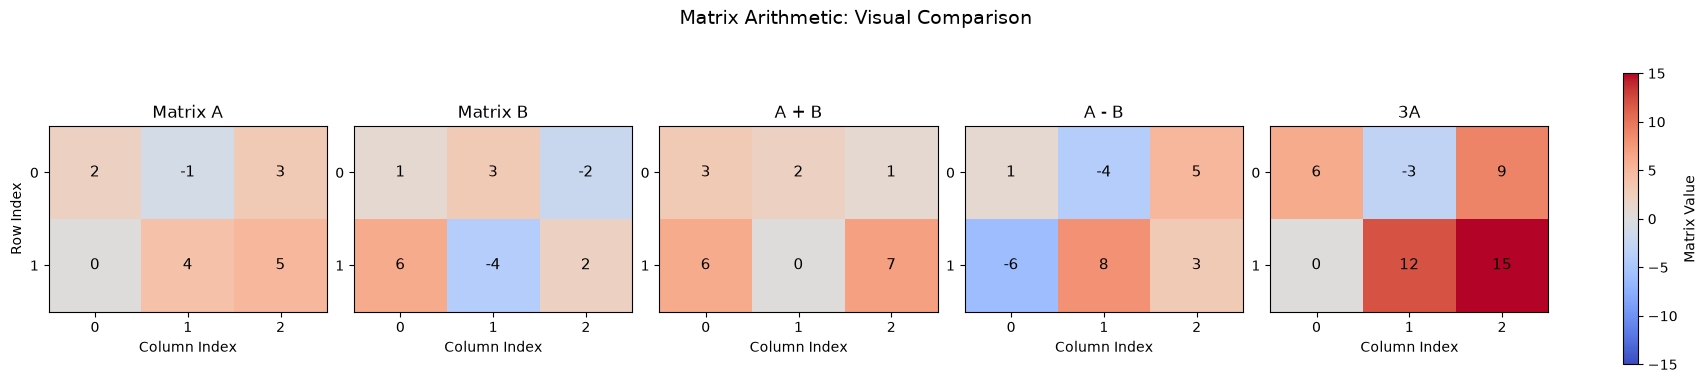

In [5]:

import matplotlib.pyplot as plt
import numpy as np

matrices = [
    A_np,
    B_np,
    addition_numpy,
    subtraction_numpy,
    scaled_numpy
]

titles = [
    "Matrix A",
    "Matrix B",
    "A + B",
    "A - B",
    "3A"
]

# Use one shared colour scale for comparison
limit = max(float(np.abs(M).max()) for M in matrices)

fig, axes = plt.subplots(
    1, 5,
    figsize=(17, 4),
    constrained_layout=True
)

for ax, M, title in zip(axes, matrices, titles):
    image = ax.imshow(
        M,
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit
    )

    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            value = M[i, j]
            ax.text(
                j, i, str(value),
                ha="center",
                va="center",
                color="black",
                fontsize=11
            )

    ax.set_title(title)
    ax.set_xlabel("Column Index")
    ax.set_xticks(range(M.shape[1]))
    ax.set_yticks(range(M.shape[0]))

axes[0].set_ylabel("Row Index")

fig.colorbar(image, ax=axes, label="Matrix Value", shrink=0.8)
fig.suptitle("Matrix Arithmetic: Visual Comparison", fontsize=14)

plt.show()



## Exercise 3 — Transpose, Identity Matrix, and Inverse

### Objective

Implement and verify three fundamental matrix operations:
transpose, identity matrix construction, and matrix inversion.

### Tasks

1. Transpose a rectangular matrix using pure Python.
2. Construct an identity matrix of a specified order.
3. Calculate the inverse of an invertible 2 x 2 matrix.
4. Verify the implementations using NumPy.
5. Confirm that transposing a matrix twice restores the original.
6. Verify the inverse using matrix multiplication.
7. Visualize the original and transformed matrices using Matplotlib.

### Mathematical Principles

For a matrix A, transposition exchanges its rows and columns:

$$
(A^T)_{ij} = A_{ji}
$$

For an identity matrix I:

$$
AI = IA = A
$$

For an invertible square matrix A:

$$
AA^{-1} = A^{-1}A = I
$$

A square matrix is invertible if and only if its determinant
is non-zero.

### Expected Learning Outcome

I should be able to implement these operations independently,
verify their mathematical properties, interpret their matrix
shapes, and visualize the results.


In [6]:

from math import isclose


def transpose_matrix_python(matrix):
    """Transpose a rectangular matrix using pure Python."""

    if not matrix or not matrix[0]:
        raise ValueError("Matrix must be non-empty.")

    if any(len(row) != len(matrix[0]) for row in matrix):
        raise ValueError("Matrix must be rectangular.")

    return [
        [matrix[row][col] for row in range(len(matrix))]
        for col in range(len(matrix[0]))
    ]


def identity_matrix_python(n):
    """Construct an n x n identity matrix."""

    if n <= 0:
        raise ValueError("Matrix size must be positive.")

    return [
        [1 if row == col else 0 for col in range(n)]
        for row in range(n)
    ]


def inverse_2x2_python(matrix):
    """Calculate the inverse of an invertible 2 x 2 matrix."""

    if len(matrix) != 2 or any(len(row) != 2 for row in matrix):
        raise ValueError("Matrix must have shape (2, 2).")

    a, b = matrix[0]
    c, d = matrix[1]

    determinant = a * d - b * c

    if isclose(determinant, 0.0, abs_tol=1e-12):
        raise ValueError("Matrix is singular and has no inverse.")

    return [
        [d / determinant, -b / determinant],
        [-c / determinant, a / determinant],
    ]


# 1. Matrix transpose
ex3_matrix = [
    [1, 2, 3],
    [4, 5, 6]
]

ex3_transpose = transpose_matrix_python(ex3_matrix)

print("Original matrix:", ex3_matrix)
print("Transposed matrix:", ex3_transpose)


# 2. Identity matrix
ex3_identity = identity_matrix_python(3)

print("\nIdentity matrix:")
for row in ex3_identity:
    print(row)


# 3. Inverse of a 2 x 2 matrix
ex3_square = [
    [4.0, 7.0],
    [2.0, 6.0]
]

ex3_inverse = inverse_2x2_python(ex3_square)

print("\nInverse matrix:")
for row in ex3_inverse:
    print(row)


Original matrix: [[1, 2, 3], [4, 5, 6]]
Transposed matrix: [[1, 4], [2, 5], [3, 6]]

Identity matrix:
[1, 0, 0]
[0, 1, 0]
[0, 0, 1]

Inverse matrix:
[0.6, -0.7]
[-0.2, 0.4]


In [7]:

import numpy as np

ex3_array = np.array(ex3_matrix)
ex3_square_np = np.array(ex3_square, dtype=float)

ex3_transpose_np = ex3_array.T
ex3_identity_np = np.eye(3)
ex3_inverse_np = np.linalg.inv(ex3_square_np)

print("Transpose matches:",
      np.array_equal(ex3_transpose, ex3_transpose_np))

print("Double transpose restores original:",
      np.array_equal(ex3_transpose_np.T, ex3_array))

print("Identity matches:",
      np.array_equal(ex3_identity, ex3_identity_np))

print("Inverse matches:",
      np.allclose(ex3_inverse, ex3_inverse_np))

print("A multiplied by inverse equals identity:",
      np.allclose(ex3_square_np @ ex3_inverse_np, np.eye(2)))

print("Inverse multiplied by A equals identity:",
      np.allclose(ex3_inverse_np @ ex3_square_np, np.eye(2)))


Transpose matches: True
Double transpose restores original: True
Identity matches: True
Inverse matches: True
A multiplied by inverse equals identity: True
Inverse multiplied by A equals identity: True


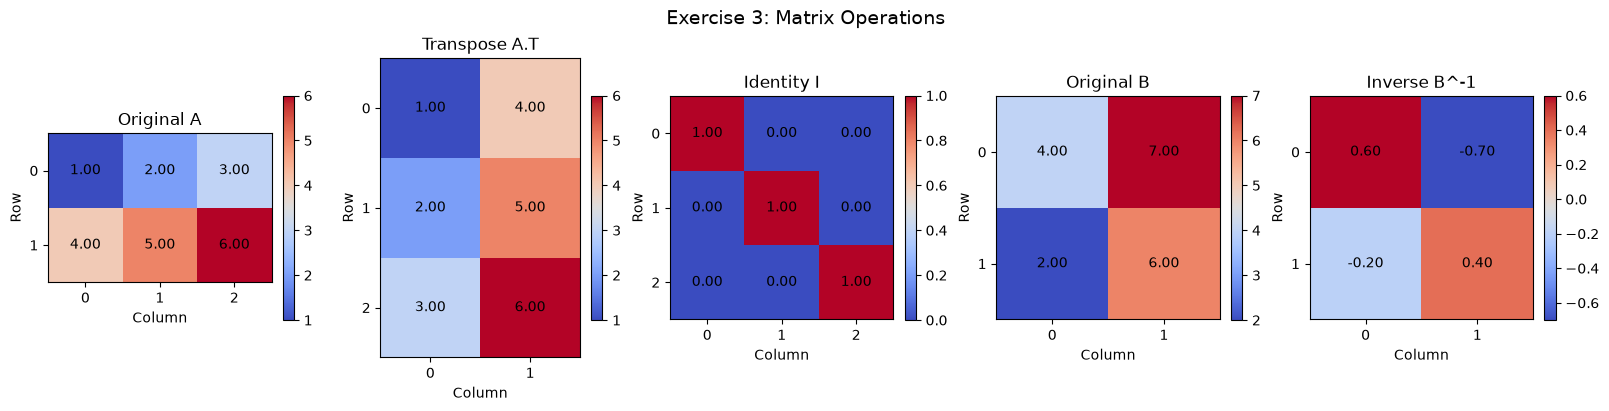

In [8]:

import matplotlib.pyplot as plt

ex3_matrices = [
    ex3_array,
    ex3_transpose_np,
    ex3_identity_np,
    ex3_square_np,
    ex3_inverse_np,
]

ex3_titles = [
    "Original A",
    "Transpose A.T",
    "Identity I",
    "Original B",
    "Inverse B^-1",
]

fig, axes = plt.subplots(
    1, 5,
    figsize=(16, 4),
    constrained_layout=True
)

for ax, matrix, title in zip(axes, ex3_matrices, ex3_titles):
    image = ax.imshow(matrix, cmap="coolwarm")

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i,
                f"{matrix[i, j]:.2f}",
                ha="center",
                va="center",
                color="black",
                fontsize=10
            )

    ax.set_title(title)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))

    fig.colorbar(image, ax=ax, shrink=0.75)

fig.suptitle("Exercise 3: Matrix Operations", fontsize=14)
plt.show()



## Written Reflection — Exercise 3

### 1. Matrix Transpose

Transposition exchanges the row and column indices of every element.
Applying the transpose operation twice restores the original matrix.

### 2. Identity Matrix

An identity matrix contains ones on its main diagonal and zeros
elsewhere. Multiplying a compatible matrix by an identity matrix
preserves the original matrix.

### 3. Matrix Inverse

The inverse of an invertible square matrix reverses its
transformation under matrix multiplication. A matrix is
invertible only when its determinant is non-zero.

### 4. Numerical Verification

NumPy was used to verify the transpose, identity matrix, and inverse.
The inverse was checked by multiplying the original matrix by its
inverse in both orders and comparing the results with the identity
matrix.

### 5. Important Limitation

The pure Python inverse implementation in this exercise supports
only 2 x 2 matrices. Larger matrices require more general numerical
methods, which will be studied in later sections.


## Exercise 4 — Matrix Multiplication and Matrix–Vector Multiplication

### Objective

Implement matrix multiplication and matrix–vector multiplication
using pure Python. Verify both implementations using NumPy and
visualize the input matrices and output matrices using Matplotlib.

### Tasks

1. Define two compatible matrices and calculate their product manually.
2. Implement matrix multiplication using nested lists and loops.
3. Verify the result using NumPy's matrix multiplication operator.
4. Implement matrix–vector multiplication using pure Python.
5. Verify the matrix–vector product using NumPy.
6. Visualize the input matrices and the resulting product.
7. Test an invalid matrix multiplication and explain why it fails.

### Mathematical Principle

If matrix A has shape (m, n) and matrix B has shape (n, p),
their product AB is defined and has shape (m, p).

Each output element is calculated by multiplying a row of A
with a column of B and summing the corresponding products.

### Expected Learning Outcome

I should be able to implement matrix multiplication independently,
reason about compatible shapes, verify numerical results, and
interpret matrix multiplication through visualizations.

In [9]:
def multiply_matrices_python(A, B):
    """Multiply two compatible rectangular matrices."""

    if not A or not B or not A[0] or not B[0]:
        raise ValueError("Matrices must be non-empty.")

    # Verify that both matrices are rectangular
    if any(len(row) != len(A[0]) for row in A):
        raise ValueError("Matrix A must be rectangular.")

    if any(len(row) != len(B[0]) for row in B):
        raise ValueError("Matrix B must be rectangular.")

    # Check multiplication compatibility
    if len(A[0]) != len(B):
        raise ValueError(
            "Columns of A must equal rows of B."
        )

    rows_A = len(A)
    cols_B = len(B[0])
    shared_dimension = len(B)

    result = []

    for i in range(rows_A):
        output_row = []

        for j in range(cols_B):
            total = 0

            for k in range(shared_dimension):
                total += A[i][k] * B[k][j]

            output_row.append(total)

        result.append(output_row)

    return result


# Define the matrices
A_list = [
    [2, -1, 3],
    [0, 4, 5]
]

B_list = [
    [1, 2],
    [3, 0],
    [-2, 1]
]

# Calculate the product
C_python = multiply_matrices_python(A_list, B_list)

print("Matrix A:", A_list)
print("Matrix B:", B_list)
print("Product AB:", C_python)
print(
    "Output shape:",
    (len(C_python), len(C_python[0]))
)

Matrix A: [[2, -1, 3], [0, 4, 5]]
Matrix B: [[1, 2], [3, 0], [-2, 1]]
Product AB: [[-7, 7], [2, 5]]
Output shape: (2, 2)


In [10]:
import numpy as np

A_np = np.array(A_list)
B_np = np.array(B_list)

C_numpy = A_np @ B_np

print("Shape of A:", A_np.shape)
print("Shape of B:", B_np.shape)

print("\nNumPy product AB:\n", C_numpy)
print("Shape of AB:", C_numpy.shape)

print(
    "\nPython and NumPy results match:",
    np.array_equal(C_python, C_numpy)
)

Shape of A: (2, 3)
Shape of B: (3, 2)

NumPy product AB:
 [[-7  7]
 [ 2  5]]
Shape of AB: (2, 2)

Python and NumPy results match: True


In [11]:
def multiply_matrix_vector_python(A, x):
    """Multiply a rectangular matrix by a compatible vector."""

    if not A or not A[0]:
        raise ValueError("Matrix must be non-empty.")

    if any(len(row) != len(A[0]) for row in A):
        raise ValueError("Matrix must be rectangular.")

    if len(A[0]) != len(x):
        raise ValueError(
            "Matrix columns must equal vector length."
        )

    return [
        sum(element * value for element, value in zip(row, x))
        for row in A
    ]


x_list = [2, -1, 3]

y_python = multiply_matrix_vector_python(A_list, x_list)

print("Input vector:", x_list)
print("Matrix-vector product:", y_python)

Input vector: [2, -1, 3]
Matrix-vector product: [14, 11]


In [12]:
x_np = np.array(x_list)

y_numpy = A_np @ x_np

print("NumPy result:", y_numpy)
print("Output shape:", y_numpy.shape)

print(
    "Results match:",
    np.array_equal(y_python, y_numpy)
)

NumPy result: [14 11]
Output shape: (2,)
Results match: True


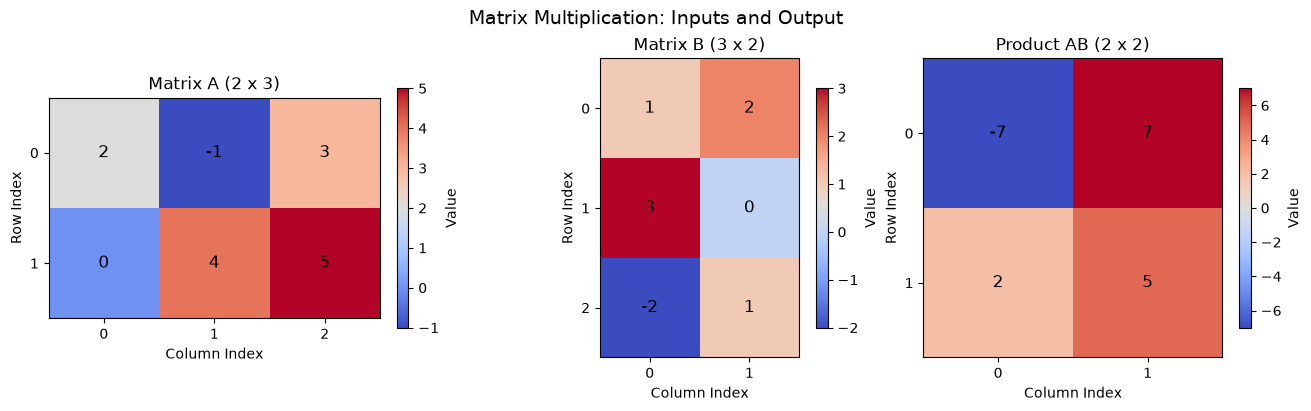

In [13]:
import matplotlib.pyplot as plt

matrices = [A_np, B_np, C_numpy]
titles = ["Matrix A (2 x 3)", "Matrix B (3 x 2)", "Product AB (2 x 2)"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    constrained_layout=True
)

for ax, matrix, title in zip(axes, matrices, titles):
    image = ax.imshow(matrix, cmap="coolwarm")

    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i,
                str(matrix[i, j]),
                ha="center",
                va="center",
                color="black",
                fontsize=12
            )

    ax.set_title(title)
    ax.set_xlabel("Column Index")
    ax.set_ylabel("Row Index")
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))

    fig.colorbar(image, ax=ax, shrink=0.8, label="Value")

fig.suptitle("Matrix Multiplication: Inputs and Output", fontsize=14)
plt.show()

In [14]:
try:
    multiply_matrices_python(
        [[1, 2, 3], [4, 5, 6]],
        [[1, 2], [3, 4]]
    )
except ValueError as error:
    print("Invalid multiplication rejected:", error)

Invalid multiplication rejected: Columns of A must equal rows of B.


## Exercise 5 — Geometric Transformations and Determinants

### Objective

Investigate how a matrix transforms geometric points and how its
determinant describes the area-scaling effect of the transformation.

### Tasks

1. Define a 2 x 2 transformation matrix.
2. Calculate its determinant using pure Python.
3. Transform the vertices of a unit square.
4. Verify the transformed coordinates using NumPy.
5. Visualize the original and transformed shapes using Matplotlib.
6. Construct a rotation matrix and verify that rotation preserves
   Euclidean lengths and area.
7. Explain the relationship between the determinant and area scaling.

### Mathematical Principles

For a 2 x 2 matrix A, the determinant is:

$$
\det(A) = ad - bc
$$

For a two-dimensional linear transformation, the area-scaling
factor is the absolute value of the determinant:

$$
\text{Area scale factor} = |\det(A)|
$$

A rotation matrix preserves Euclidean lengths and area.

### Expected Learning Outcome

I should be able to calculate determinants, transform geometric
points using matrix multiplication, verify numerical results, and
interpret these transformations through visualizations.

In [15]:

def determinant_2x2_python(matrix):
    """Calculate the determinant of a 2 x 2 matrix."""
    if len(matrix) != 2 or any(len(row) != 2 for row in matrix):
        raise ValueError("Matrix must have shape (2, 2).")

    a, b = matrix[0]
    c, d = matrix[1]

    return a * d - b * c


def transform_points_python(points, matrix):
    """Transform 2D points using a 2 x 2 matrix."""

    if len(matrix) != 2 or any(len(row) != 2 for row in matrix):
        raise ValueError("Transformation matrix must have shape (2, 2).")

    transformed = []

    for point in points:
        if len(point) != 2:
            raise ValueError("Each point must have two coordinates.")

        x, y = point

        new_x = matrix[0][0] * x + matrix[0][1] * y
        new_y = matrix[1][0] * x + matrix[1][1] * y

        transformed.append([new_x, new_y])

    return transformed


# Transformation matrix
T_list = [
    [2, 1],
    [1, 2]
]

# Vertices of a unit square; repeat the first vertex to close it
square_points = [
    [0, 0],
    [1, 0],
    [1, 1],
    [0, 1],
    [0, 0]
]

det_python = determinant_2x2_python(T_list)
transformed_python = transform_points_python(square_points, T_list)

print("Determinant:", det_python)
print("Area scale factor:", abs(det_python))
print("Transformed points:", transformed_python)


Determinant: 3
Area scale factor: 3
Transformed points: [[0, 0], [2, 1], [3, 3], [1, 2], [0, 0]]


In [16]:

import numpy as np

T_np = np.array(T_list, dtype=float)
square_np = np.array(square_points, dtype=float)

# Verify the determinant and transformed points
det_numpy = np.linalg.det(T_np)
transformed_numpy = square_np @ T_np.T

print("NumPy determinant:", det_numpy)
print(
    "Determinants match:",
    np.isclose(det_python, det_numpy)
)
print(
    "Transformed points match:",
    np.allclose(transformed_python, transformed_numpy)
)

# Construct a 30-degree counterclockwise rotation matrix
angle_degrees = 30
angle_radians = np.deg2rad(angle_degrees)

R_np = np.array([
    [np.cos(angle_radians), -np.sin(angle_radians)],
    [np.sin(angle_radians),  np.cos(angle_radians)]
])

rotated_numpy = square_np @ R_np.T

print("\nRotation determinant:", np.linalg.det(R_np))
print(
    "Rotation preserves area:",
    np.isclose(abs(np.linalg.det(R_np)), 1.0)
)


NumPy determinant: 2.9999999999999996
Determinants match: True
Transformed points match: True

Rotation determinant: 1.0
Rotation preserves area: True


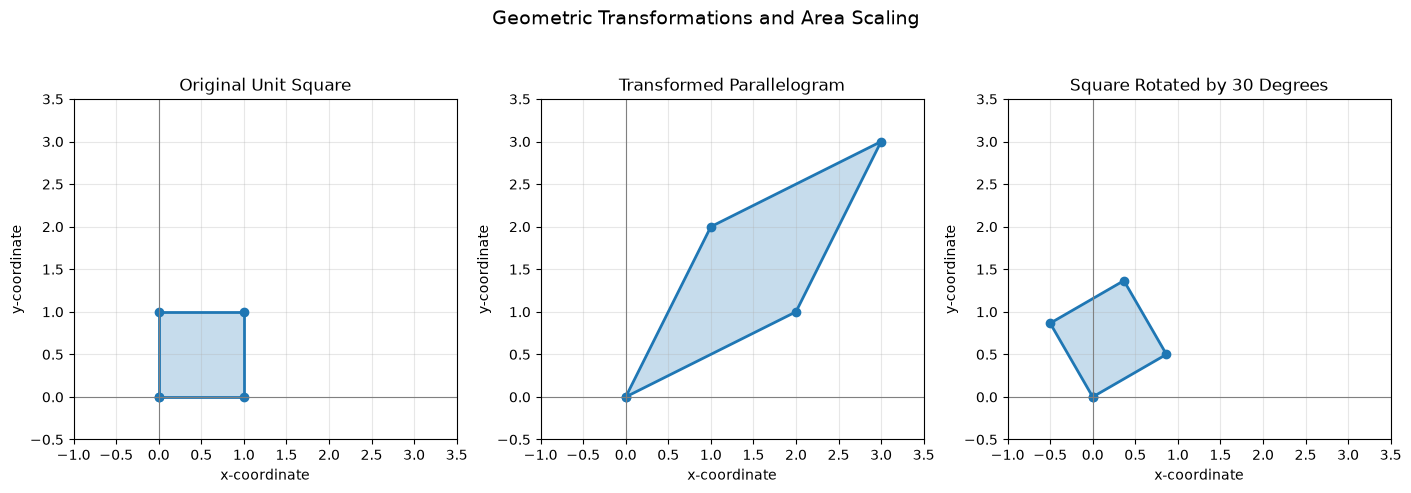

In [17]:

import matplotlib.pyplot as plt

all_points = np.vstack([
    square_np,
    transformed_numpy,
    rotated_numpy
])

padding = 0.5
x_min = all_points[:, 0].min() - padding
x_max = all_points[:, 0].max() + padding
y_min = all_points[:, 1].min() - padding
y_max = all_points[:, 1].max() + padding

point_sets = [
    square_np,
    transformed_numpy,
    rotated_numpy
]

titles = [
    "Original Unit Square",
    "Transformed Parallelogram",
    "Square Rotated by 30 Degrees"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 5),
    constrained_layout=True
)

for ax, points, title in zip(axes, point_sets, titles):
    ax.fill(
        points[:, 0],
        points[:, 1],
        alpha=0.25
    )

    ax.plot(
        points[:, 0],
        points[:, 1],
        marker="o",
        linewidth=2
    )

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)

    ax.set_title(title)
    ax.set_xlabel("x-coordinate")
    ax.set_ylabel("y-coordinate")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Geometric Transformations and Area Scaling",
    fontsize=14
)

plt.show()


## Exercise 6 — Written Reflection

### 1. Difference Between Matrix Shape and Dimensions

The shape of a matrix describes its number of rows and columns,
whereas the number of dimensions of a NumPy matrix indicates
the number of axes in its array representation.

For example, a NumPy array with shape (3, 2) contains three rows,
two columns, six elements, and two dimensions.

### 2. Matrix Addition and Subtraction

Standard matrix addition and subtraction require both matrices
to have identical shapes because corresponding elements must
be paired together.

NumPy performs these operations element-wise for compatible
arrays. However, NumPy broadcasting can allow some operations
between different shapes; this does not change the standard
matrix-addition rule studied in this topic.

### 3. Difference Between Element-wise and Matrix Multiplication

Element-wise multiplication combines corresponding elements
of compatible arrays.

Matrix multiplication calculates each output element using
the dot product of a row from the first matrix and a column
from the second matrix.

For compatible shapes (m, n) and (n, p), the product has shape
(m, p).

### 4. Matrix Transpose, Identity, and Inverse

Transposition exchanges rows and columns. An identity matrix
contains ones on the main diagonal and zeros elsewhere.

An invertible square matrix has a unique inverse that satisfies
A A^{-1} = A^{-1} A = I.

A square matrix has an ordinary inverse when its determinant
is non-zero.

### 5. Determinant and Geometric Transformations

The absolute value of the determinant of a two-dimensional
linear transformation gives its area-scaling factor.

A rotation matrix has determinant 1 and preserves lengths,
angles, and area. A transformation with determinant magnitude
3 multiplies the area of a region by 3.

A negative determinant indicates an orientation reversal.

### 6. Role of NumPy and Matplotlib

NumPy provides efficient numerical operations and functions
for verifying matrix calculations.

Matplotlib helps visualize matrix values, coordinate
transformations, and geometric changes. These visualizations
make mathematical properties easier to interpret.

### 7. Importance of Numerical Verification

Comparing independently written Python implementations with
NumPy helps detect logical errors and incorrect calculations.

Floating-point results should often be compared with suitable
numerical tolerances instead of exact equality.

### 8. Learning Outcome

This exercise strengthened my understanding of matrix
representation, matrix arithmetic, transpose, identity,
inverse, multiplication, determinants, and geometric
transformations through mathematical reasoning, Python
implementation, NumPy verification, and visualization.